# Tech Challenge Fase 1 — Apoio ao diagnóstico de câncer de mama
Protótipo acadêmico: classificar tumores como **maligno (1)** ou **benigno (0)** a partir do dataset público
*Breast Cancer Wisconsin (Diagnostic)*. O modelo é **apoio à decisão** — a palavra final é sempre do médico.

Este notebook apenas chama as funções de `src/` (onde está a lógica testada) e discute os resultados,
seguindo a ordem do enunciado: dados → exploração → pré-processamento → modelos → avaliação → interpretação.

In [1]:
# Permite importar src/ a partir da pasta notebooks/
import sys; sys.path.append("..")
import pandas as pd
from IPython.display import Image, display
from src import data, eda, preprocessing, train, evaluate, explain

## 1. Problema e dados
O dataset tem 569 exames (aspirado por agulha fina) com 30 medidas numéricas do núcleo celular
(raio, textura, concavidade... em três versões: média, erro-padrão e "pior"). Não há valores ausentes
nem variáveis categóricas, então a limpeza se resume a verificar isso (feito em `tests/test_data.py`).

In [2]:
df = data.load_data()
print(df.shape); df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Exploração (EDA)
**Balanceamento:** 63% benigno / 37% maligno — desbalanceamento moderado. Por isso não usamos só accuracy
(um modelo que chuta "benigno" acertaria 63%) e priorizamos **recall** da classe maligna.

In [3]:
display(eda.class_balance(df))
eda.describe(df).round(3)

,n,proporcao
target,,
benigno,357,0.627
maligno,212,0.373


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


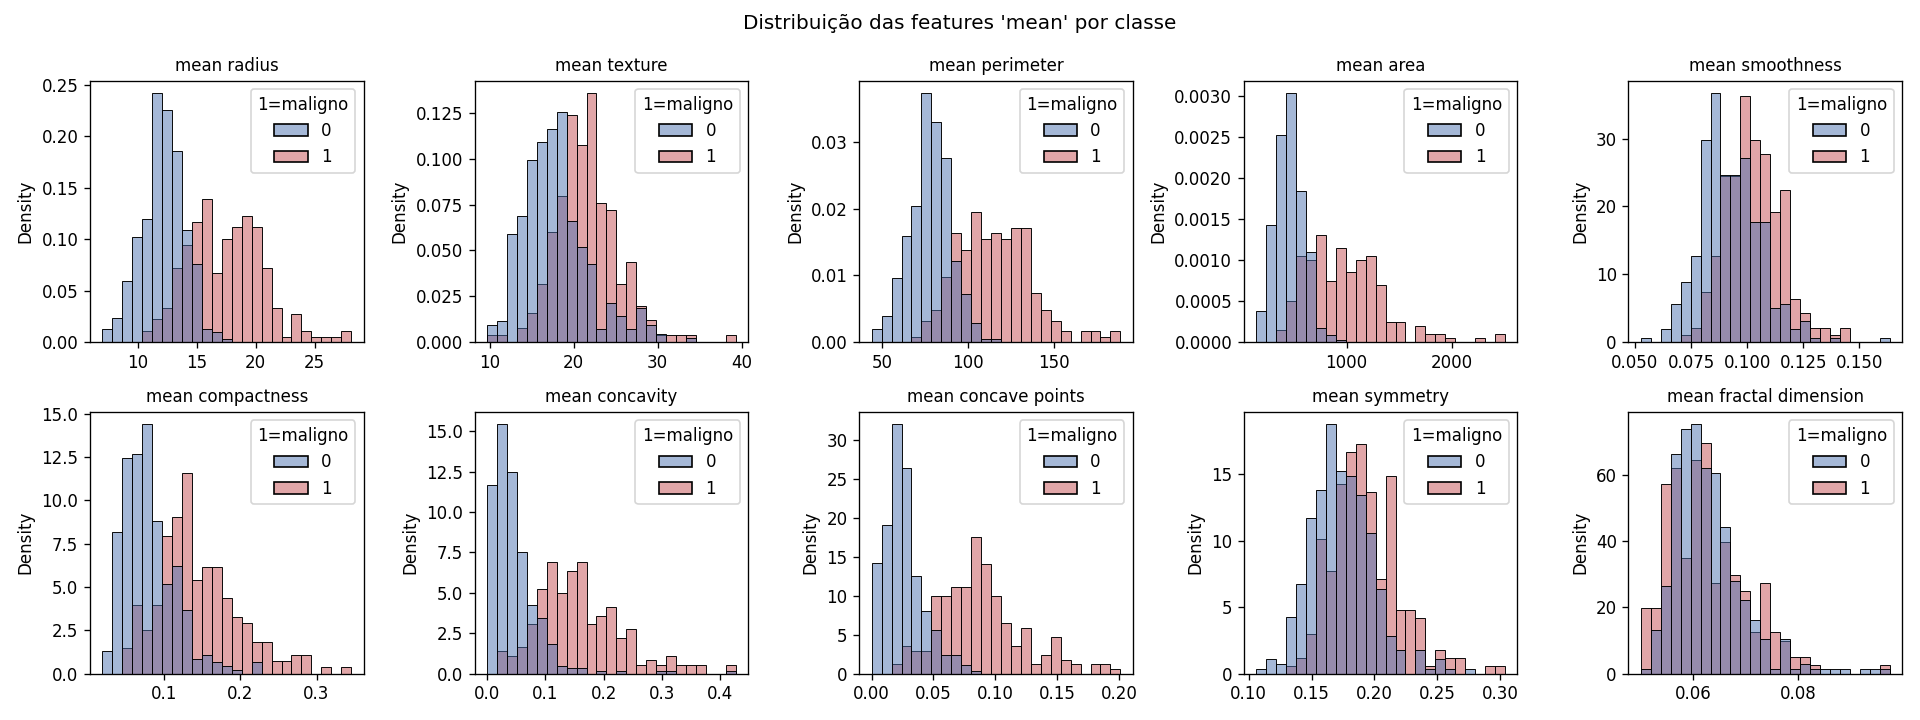

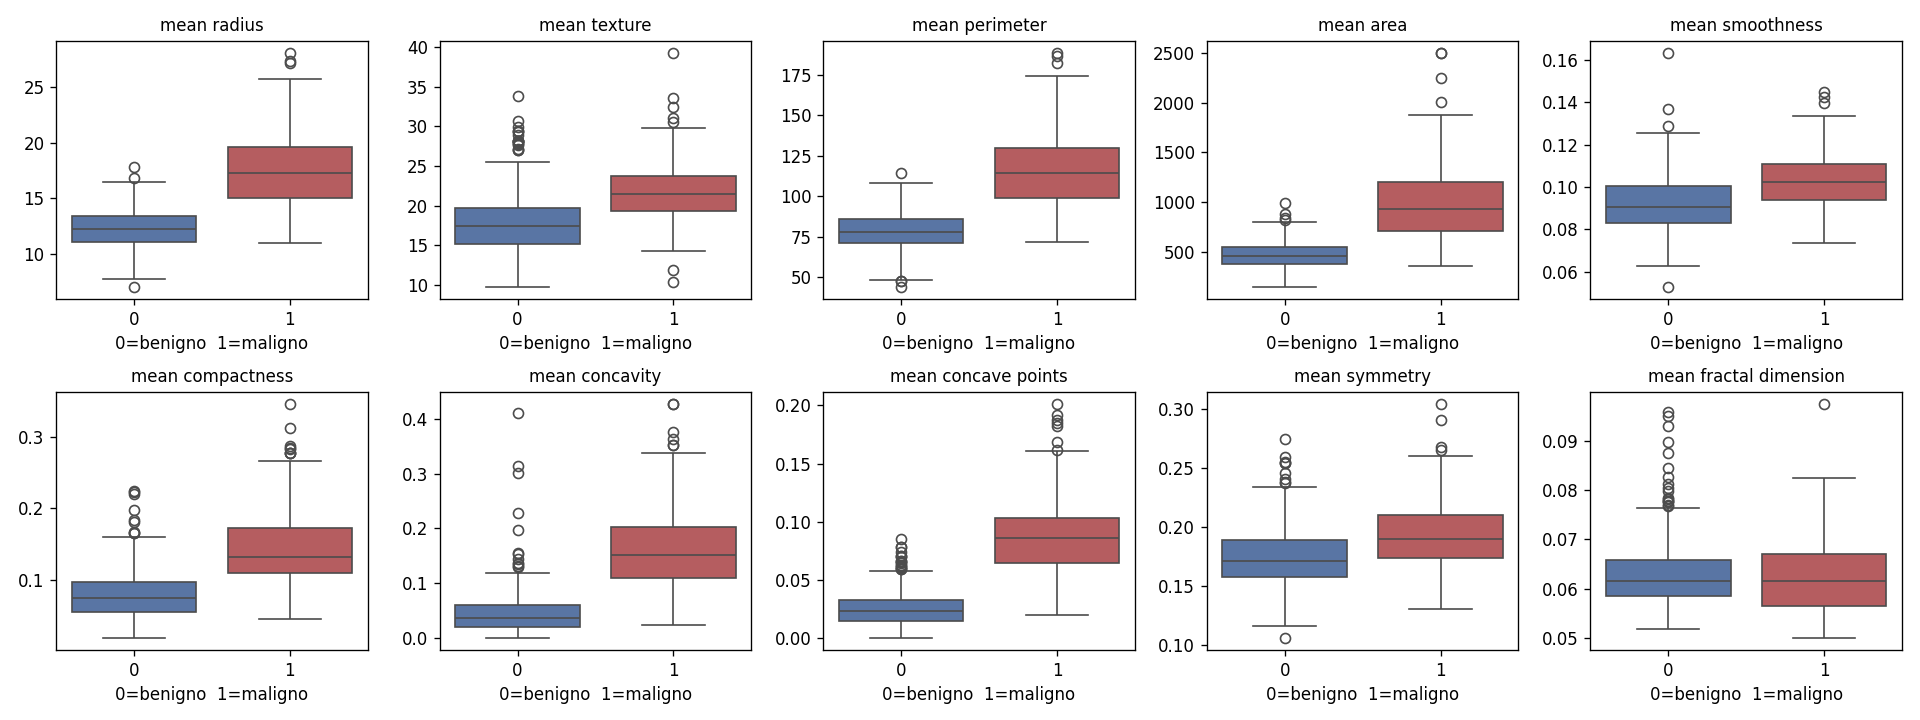

In [4]:
display(Image(eda.plot_distributions(df)))
display(Image(eda.plot_boxplots(df)))

**Discussão:** features de tamanho (`radius`, `perimeter`, `area`) e de forma (`concavity`, `concave points`)
separam bem as classes — malignos são maiores e mais irregulares. `smoothness`, `symmetry` e `fractal dimension`
quase não separam. Há outliers, mas são casos reais (tumores grandes), não erros — mantidos.

worst concave points    0.794
worst perimeter         0.783
mean concave points     0.777
worst radius            0.776
mean perimeter          0.743
worst area              0.734
mean radius             0.730
mean area               0.709
mean concavity          0.696
worst concavity         0.660
Name: target, dtype: float64

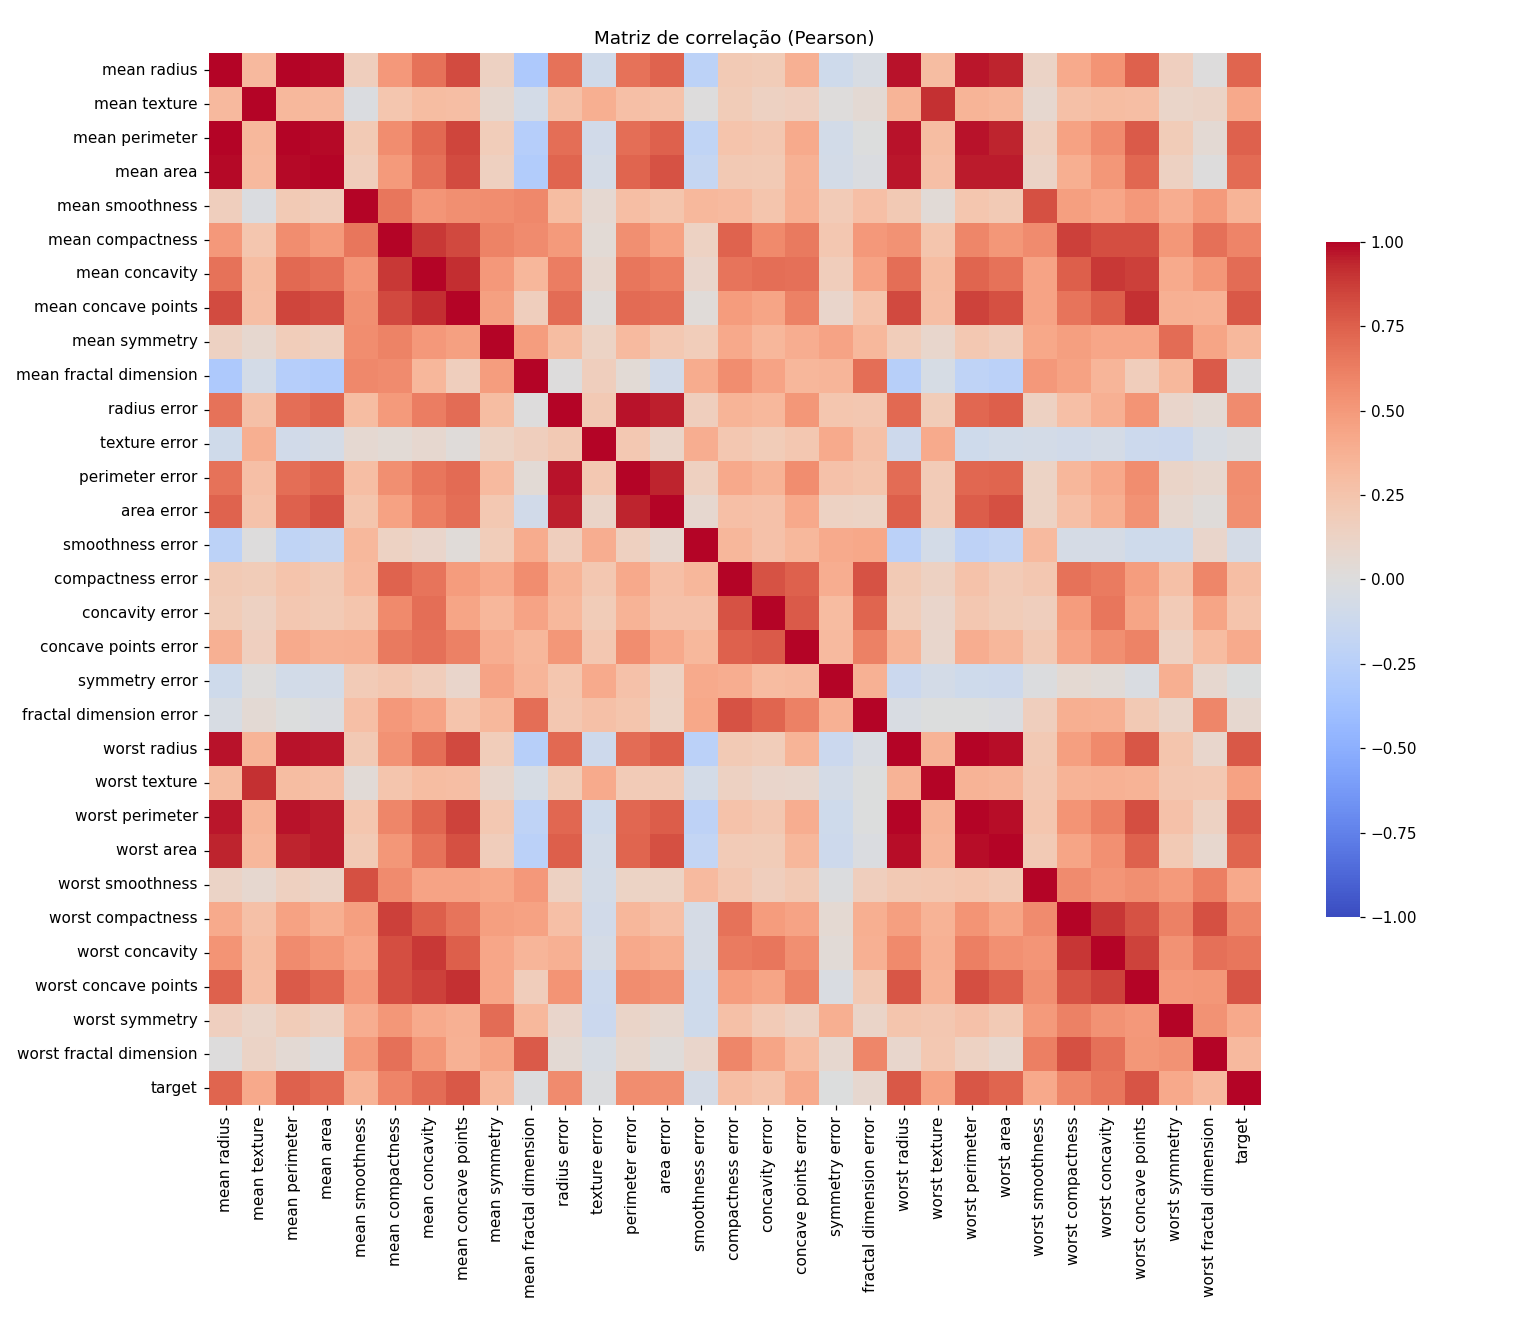

In [5]:
display(eda.top_correlated_with_target(df).round(3))
display(Image(eda.plot_correlation(df)))

**Correlação:** `worst concave points` (0,79), `worst perimeter` (0,78) e `mean concave points` (0,78) lideram.
O heatmap mostra blocos com r≈0,99 (radius/perimeter/area): **multicolinearidade** forte. Consequências:
usamos regularização L2 na regressão logística e lemos importâncias individuais com cautela.

## 3. Pré-processamento e separação
- Split **estratificado** 60/20/20 (treino 341 / validação 114 / teste 114), `random_state=42`.
- `StandardScaler` dentro de um `Pipeline`: ajustado só no treino → **sem data leakage**.
- Validação escolhe o modelo; teste é usado **uma única vez** no final.

In [6]:
X_tr, X_va, X_te, y_tr, y_va, y_te = preprocessing.split_data(df)
pd.DataFrame({"treino": y_tr.value_counts(), "validacao": y_va.value_counts(), "teste": y_te.value_counts()})

,treino,validacao,teste
target,,,
0,214,71,72
1,127,43,42


## 4. Modelos e treinamento
Dois modelos simples e complementares: **Regressão Logística** (linear, interpretável, baseline) e
**Random Forest** (não linear, `class_weight="balanced"`). Métricas na **validação**:

In [7]:
train.train_all().round(4)

,accuracy,recall,f1
modelo,,,
logistic_regression,0.9737,0.9767,0.9655
random_forest,0.9737,0.9535,0.9647


## 5. Avaliação no teste
**Por que estas métricas?** Recall = fração de malignos detectados (falso negativo é o erro mais grave:
atrasa tratamento). F1 equilibra recall e precisão (evita marcar tudo como maligno → biópsias desnecessárias).
Accuracy fica como visão geral.

In [8]:
evaluate.evaluate_all().round(4)

,accuracy,recall,f1,tn,fp,fn,tp
modelo,,,,,,,
logistic_regression,0.9737,0.9524,0.9639,71,1,2,40
random_forest,0.9561,0.9048,0.9383,71,1,4,38


**Resultado:** a Regressão Logística venceu na validação e confirmou no teste — recall 0,95 (2 falsos negativos
em 42 malignos), 1 falso positivo, F1 0,96. A Random Forest teve 4 falsos negativos. Modelo escolhido: **Regressão Logística**.

## 6. Interpretação — Feature Importance e SHAP

,logistic_regression,random_forest
worst texture,0.082,0.024
mean concave points,0.067,0.118
radius error,0.062,0.012
worst symmetry,0.058,0.013
worst radius,0.049,0.057
worst area,0.048,0.104
area error,0.048,0.028
worst concavity,0.047,0.036
mean concavity,0.046,0.060
compactness error,0.046,0.005


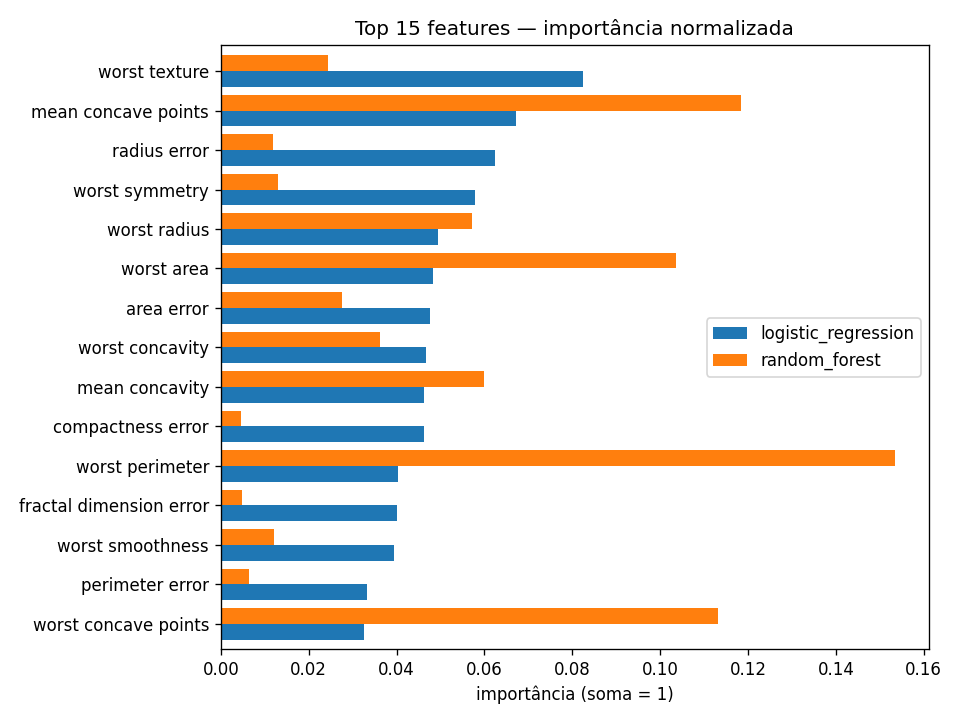

In [9]:
display(explain.feature_importance().head(10).round(3))
display(Image(explain.plot_feature_importance()))

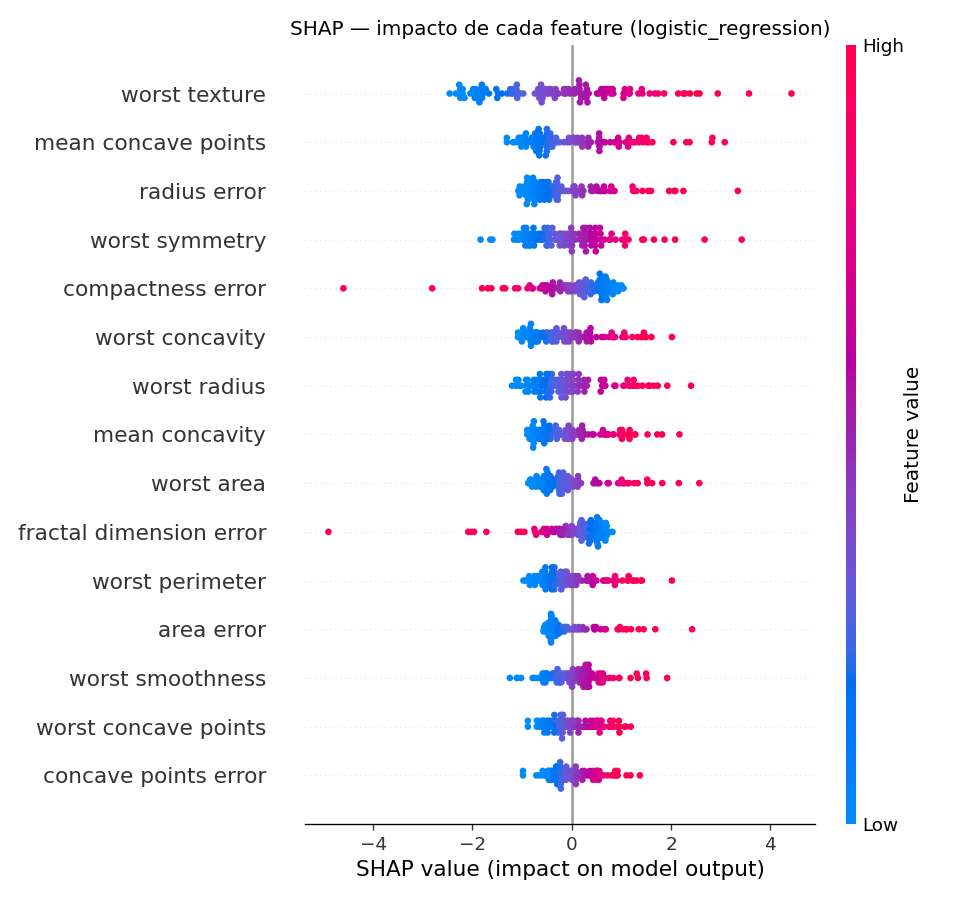

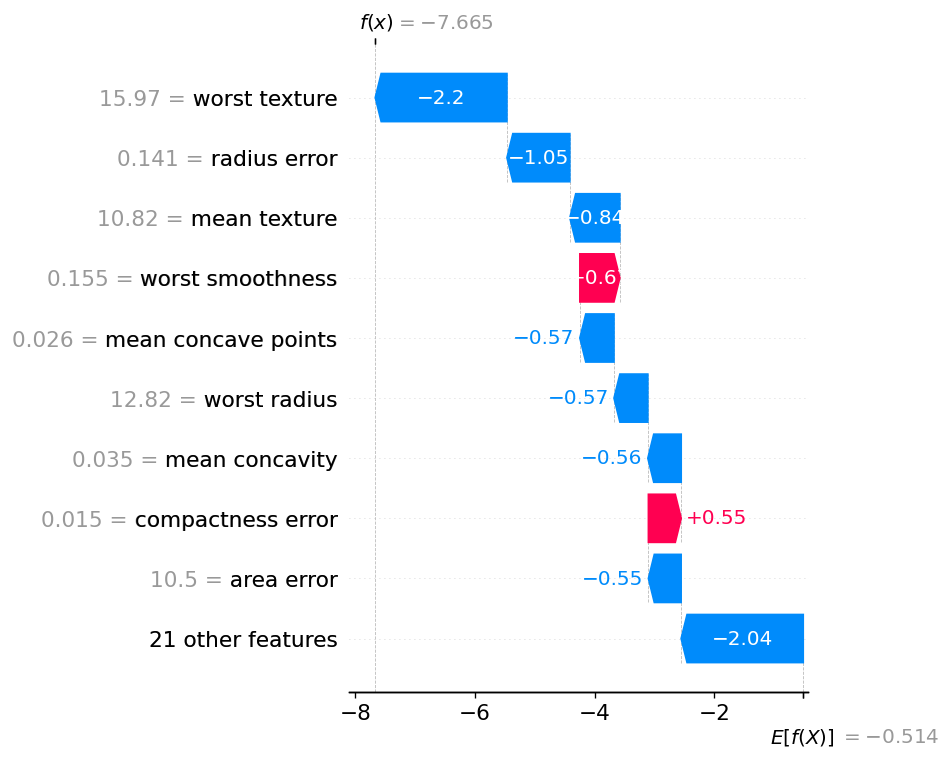

In [10]:
display(Image(explain.plot_shap_summary()))
display(Image(explain.plot_shap_individual(i=0)))

**Leitura:** valores altos de `worst texture`, `mean concave points`, `radius error` e `worst symmetry` empurram
para maligno; `compactness error` e `fractal dimension error` altos empurram para benigno. O ranking do modelo
difere da correlação simples (efeito da multicolinearidade: o peso se distribui entre features redundantes).
O gráfico *waterfall* explica **um paciente**: é o que o médico vê no app para julgar se a sugestão faz sentido.

## 7. Discussão crítica — pode ser usado na prática?
**Como apoio, sim; como diagnóstico, não.**
- Mesmo o melhor modelo deixa passar ~5% dos malignos no teste; em triagem isso exige que o médico revise todo caso,
  especialmente os de probabilidade intermediária.
- O dataset é pequeno (569), de um único centro e antigo — pode não representar outra população/equipamento
  (*dataset shift*). Antes de uso real seria preciso validação externa e prospectiva.
- As features vêm de uma medição laboratorial padronizada; o modelo não substitui o exame, só organiza sua leitura.
- O SHAP dá transparência caso a caso, mas explica o **modelo**, não a biologia.
- Fluxo proposto: exame → modelo (probabilidade) → SHAP → **avaliação humana** → decisão final do médico.